<a href="https://colab.research.google.com/github/FridaOyucho/HTS-Model-/blob/main/xGBoostModelreviewed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install --upgrade pandas numpy scikit-learn xgboost

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score,classification_report
from xgboost import XGBClassifier
import pickle
from sklearn.metrics import average_precision_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Import datasets

In [4]:
import pandas as pd

sparse = {
    "sparse_train": pd.read_csv("sparse_train (1).csv"),
    "sparse_val": pd.read_csv("sparse_val (1).csv"),
    "sparse_test": pd.read_csv("sparse_test (1).csv")
}

print(sparse.keys())

dict_keys(['sparse_train', 'sparse_val', 'sparse_test'])


In [5]:
print(sparse.keys())

dict_keys(['sparse_train', 'sparse_val', 'sparse_test'])


In [6]:
for name, hts in sparse.items():
  print(name, hts.shape)

sparse_train (1271440, 56)
sparse_val (423814, 56)
sparse_test (423814, 56)


In [7]:
cols_to_drop = ["EMR", "SDP","PatientPk","MFL_Code","SiteCode","Latitude","Longitude","Facility_Name", "SubCounty",
                "ClientTestedAs","CoupleDiscordant","VisitDate","NumberOfPartners"]

for key in sparse.keys():
  sparse[key] = sparse[key].drop(columns=cols_to_drop, errors="ignore")


In [8]:
#Check dtypes
for name, df in sparse.items():
    print(f"\n{name}")
    print(df.dtypes.value_counts())



sparse_train
str        42
float64     1
Name: count, dtype: int64

sparse_val
str        42
float64     1
Name: count, dtype: int64

sparse_test
str        42
float64     1
Name: count, dtype: int64


Prepare train, validation and test sets

In [9]:
#define features and target variable
X_train = sparse["sparse_train"].drop(columns=["FinalTestResult"])
y_train = sparse["sparse_train"]["FinalTestResult"]

X_val = sparse["sparse_val"].drop(columns=["FinalTestResult"])
y_val = sparse["sparse_val"]["FinalTestResult"]

X_test = sparse["sparse_test"].drop(columns=["FinalTestResult"])
y_test = sparse["sparse_test"]["FinalTestResult"]

Encode categorical variables

In [10]:
dtype_summary = pd.DataFrame({
    "Variable": X_train.columns,
    "Datatype": X_train.dtypes.astype(str)
})

dtype_summary = dtype_summary.sort_values("Datatype")

dtype_summary.head(100)

,Variable,Datatype
Age,Age,float64
PopulationType,PopulationType,str
KeyPopulation,KeyPopulation,str
PriorityPopulation,PriorityPopulation,str
IsHealthWorker,IsHealthWorker,str
TestedHIVBefore,TestedHIVBefore,str
ResultOfHIV,ResultOfHIV,str
EverHadSex,EverHadSex,str
SexuallyActive,SexuallyActive,str
NewPartner,NewPartner,str


In [11]:
for name in sparse:
    obj_cols = sparse[name].select_dtypes(include=['string', 'str']).columns
    sparse[name][obj_cols] = sparse[name][obj_cols].astype(object)

In [12]:
for name, df in sparse.items():
    print(df.dtypes.value_counts())

object     42
float64     1
Name: count, dtype: int64
object     42
float64     1
Name: count, dtype: int64
object     42
float64     1
Name: count, dtype: int64


In [13]:
for col in X_train.columns:
    print(col, X_train[col].nunique())


PopulationType 3
KeyPopulation 5
PriorityPopulation 1
IsHealthWorker 3
TestedHIVBefore 2
ResultOfHIV 2
EverHadSex 3
SexuallyActive 5
NewPartner 4
PartnerHIVStatus 5
MultiplePartners 3
AlcoholSex 5
MoneySex 4
CondomBurst 4
UnknownStatusPartner 4
KnownStatusPartner 4
Pregnant 4
BreastfeedingMother 4
ExperiencedViolenceScreening 4
CurrentlyOnPrep 3
TraditionalProcedures 2
MothersStatus 4
ResultOfHIVSelf 2
ScreenedTB 3
TBStatus 4
ReceivedServices 9
ViolenceScreeningType 9
Sex 2
MaritalStatus 7
PatientDisabled 2
EverTestedForHiv 2
MonthsSinceLastTest 5
PriorityPopulationType 5
County 40
Age 99
GBVSexual 3
GBVPhysical 3
GBVEmotional 3
ReceivedPREP 2
ReceivedTB 2
ReceivedSTI 2
dayofweek 7


In [80]:
# One-hot encode categorical features into sparse matrices
from scipy import sparse as scipy_sparse
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns

encoder = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", dtype=np.float32), categorical_cols)
    ],
    remainder="passthrough",
    sparse_threshold=1.0,
)

X_train_enc = scipy_sparse.csr_matrix(encoder.fit_transform(X_train))
X_val_enc = scipy_sparse.csr_matrix(encoder.transform(X_val))
X_test_enc = scipy_sparse.csr_matrix(encoder.transform(X_test))
encoded_feature_names = encoder.get_feature_names_out()

In [15]:
# Verify that all splits have the same encoded features
print(X_train_enc.shape[1] == X_val_enc.shape[1])
print(X_train_enc.shape[1] == X_test_enc.shape[1])

True
True


In [16]:
# Preview a small dense slice without expanding the full sparse matrix
pd.DataFrame(
    X_train_enc[:5, :10].toarray(),
    columns=encoded_feature_names[:10],
)

,categorical__PopulationType_GP,categorical__PopulationType_KP,categorical__PopulationType_PRIORITY,categorical__KeyPopulation_FSW,categorical__KeyPopulation_MSM,categorical__KeyPopulation_NR,categorical__KeyPopulation_PRISONER,categorical__KeyPopulation_PWID,categorical__KeyPopulation_nan,categorical__PriorityPopulation_NR
0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [17]:
print("shape:", X_train_enc.shape)
print("dtype:", X_train_enc.dtype)
print("stored nonzeros:", X_train_enc.nnz)

shape: (1271440, 224)
dtype: float64
stored nonzeros: 53400480


In [18]:
density = X_train_enc.nnz / (X_train_enc.shape[0] * X_train_enc.shape[1])
print(f"Sparse matrix density: {density:.6f}")

Sparse matrix density: 0.187500


Encode target variable

In [19]:
#Check the output, if not in numericals, encode it
print(y_train.value_counts())

FinalTestResult
NEGATIVE    1239327
POSITIVE      32113
Name: count, dtype: int64


In [20]:
# Encode target labels using the training-set mapping
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

In [21]:
#Calculate this if positivity is much fewer than negatives: This is because HIV positivity is usually imbalanced
neg = (y_train_enc == 0).sum()
pos = (y_train_enc == 1).sum()

scale_pos_weight = neg / pos

print(scale_pos_weight)

38.592688319372215


Train XGBoost

In [ ]:
# CHANGED: Define the hyperparameter grid and retain the best model/results.
from itertools import product
import time
import pandas as pd

max_depths = [5]
learning_rates = [0.05]
scale_pos_weights = [1]
subsamples = [0.8]

# CHANGED: Store every validation score instead of only overwriting xgb_model.
results = []
best_model = None
best_score = float("-inf")
best_params = None

# CHANGED: Track progress and estimate the remaining runtime.
configurations = list(product(
    max_depths,
    learning_rates,
    scale_pos_weights,
    subsamples
))
total_runs = len(configurations)
search_start = time.perf_counter()

for run_number, (max_depth, learning_rate, scale_pos_weight, subsample) in enumerate(
    configurations, start=1
):
    print(
        f"Starting {run_number}/{total_runs} ({run_number / total_runs:.1%}): "
        f"depth={max_depth}, lr={learning_rate}, spw={scale_pos_weight}, "
        f"subsample={subsample}",
        flush=True,
    )

    xgb_model = XGBClassifier(
        n_estimators=1000,
        max_depth=max_depth,
        learning_rate=learning_rate,
        scale_pos_weight=scale_pos_weight,
        subsample=subsample,
        random_state=2231,
        eval_metric="aucpr",
        early_stopping_rounds=50,
        n_jobs=-1
    )

    xgb_model.fit(
        X_train_enc,
        y_train_enc,
        eval_set=[(X_val_enc, y_val_enc)],
        verbose=False
    )

    score = xgb_model.best_score
    params = {
        "max_depth": max_depth,
        "learning_rate": learning_rate,
        "scale_pos_weight": scale_pos_weight,
        "subsample": subsample,
    }
    results.append({
        **params,
        "validation_aucpr": score,
        "best_iteration": xgb_model.best_iteration,
    })

    # CHANGED: Select the model using validation AUPRC, matching eval_metric.
    if score > best_score:
        best_score = score
        best_model = xgb_model
        best_params = params

    elapsed = time.perf_counter() - search_start
    average_time = elapsed / run_number
    eta_seconds = average_time * (total_runs - run_number)
    print(
        f"Completed {run_number}/{total_runs}; "
        f"AUPRC={score:.5f}; "
        f"elapsed={elapsed / 60:.1f} min; "
        f"ETA={eta_seconds / 60:.1f} min",
        flush=True,
    )

results_df = (
    pd.DataFrame(results)
    .sort_values("validation_aucpr", ascending=False)
    .reset_index(drop=True)
)

results_df.to_csv("xgb_hyperparameter_results.csv", index=False)

expected_runs = len(configurations)
print(f"Completed {len(results)} of {expected_runs} configurations")
print("Best parameters:", best_params)
print("Best validation AUPRC:", best_score)
print("Best iteration:", best_model.best_iteration)
results_df.head(10)

Starting 1/1 (100.0%): depth=5, lr=0.05, spw=1, subsample=0.8
Completed 1/1; AUPRC=0.24761; elapsed=72.9 min; ETA=0.0 min
Completed 1 of 1 configurations
Best parameters: {'max_depth': 5, 'learning_rate': 0.05, 'scale_pos_weight': 1, 'subsample': 0.8}
Best validation AUPRC: 0.24761419682209027
Best iteration: 999


,max_depth,learning_rate,scale_pos_weight,subsample,validation_aucpr,best_iteration
0,5,0.05,1,0.8,0.247614,999


In [ ]:
import joblib
from google.colab import files

# Save models
joblib.dump(xgb_model, '/content/xgb_model.pkl')
joblib.dump(best_model, '/content/best_model.pkl')

# Download models
files.download('/content/xgb_model.pkl')
files.download('/content/best_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:

# Load models
xgb_model = joblib.load('/content/xgb_model (1).pkl')
best_model = joblib.load('/content/best_model (1).pkl')

# Confirm loading
print(type(xgb_model))
print(type(best_model))

<class 'xgboost.sklearn.XGBClassifier'>
<class 'xgboost.sklearn.XGBClassifier'>


In [22]:
# Predictions on the Val set
y_pred = best_model.predict(X_val_enc)

precision = precision_score(y_val_enc, y_pred)
recall = recall_score(y_val_enc, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Precision: 0.6429
Recall: 0.0616


Checking the maximum threshhold at maximum precision at 90%  and 95% sensitivity

In [23]:
from sklearn.metrics import precision_recall_curve


y_scores = best_model.predict_proba(X_test_enc)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test_enc,
    y_scores
)

operating_points = {}

for target in [0.90, 0.95]:

    valid = np.where(recall >= target)[0]

    if len(valid) == 0:
        print(f"No threshold achieves {target:.0%} sensitivity")
        continue

    idx = valid[-1]

    operating_points[target] = {
        "threshold": thresholds[idx],
        "recall": recall[idx],
        "precision": precision[idx]
    }

    print(f"\nTarget sensitivity: {target:.0%}")
    print(f"Actual sensitivity: {recall[idx]:.4f}")
    print(f"Precision: {precision[idx]:.4f}")
    print(f"Threshold: {thresholds[idx]:.6f}")


Target sensitivity: 90%
Actual sensitivity: 0.9000
Precision: 0.0520
Threshold: 0.012169

Target sensitivity: 95%
Actual sensitivity: 0.9500
Precision: 0.0426
Threshold: 0.007738


Test the model at 90% sensitivity

In [35]:
#Define the threshhold
threshold_90 = operating_points[0.90]['threshold']

print(operating_points[0.90])

y_pred_90 = (
    best_model.predict_proba(X_test_enc)[:,1]
    >= threshold_90
).astype(int)

print(classification_report(
    y_test_enc,
    y_pred_90,
    digits=4
))

{'threshold': np.float32(0.012168635), 'recall': np.float64(0.9000373692077728), 'precision': np.float64(0.05196584515968952)}
              precision    recall  f1-score   support

           0     0.9955    0.5746    0.7286    413110
           1     0.0520    0.9000    0.0983     10704

    accuracy                         0.5828    423814
   macro avg     0.5237    0.7373    0.4134    423814
weighted avg     0.9717    0.5828    0.7127    423814



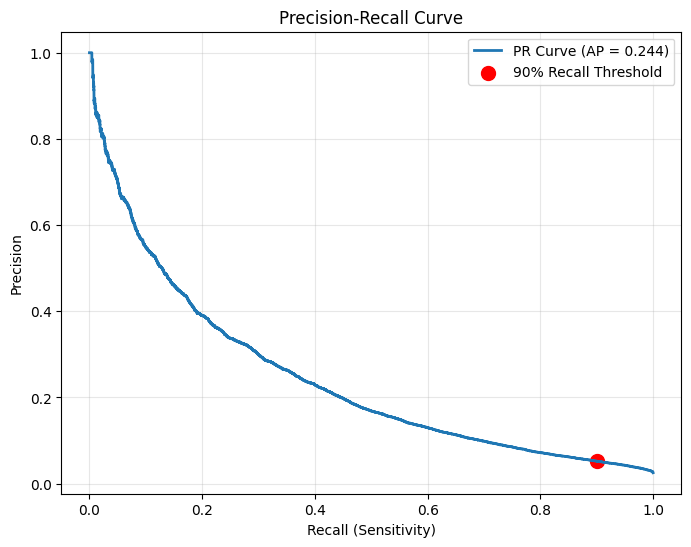

In [36]:
#Recall Curve
# Probabilities
y_prob = best_model.predict_proba(X_test_enc)[:, 1]

# PR curve
precisions, recalls, thresholds = precision_recall_curve(
    y_test_enc,
    y_prob
)

ap = average_precision_score(y_test_enc, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, linewidth=2,
         label=f'PR Curve (AP = {ap:.3f})')

# Mark the 90% recall operating point
plt.scatter(
    0.90,
    0.0520,
    color='red',
    s=100,
    label='90% Recall Threshold'
)

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

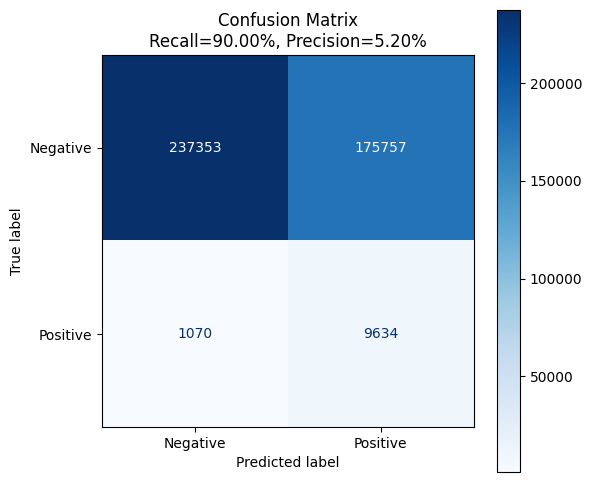

In [37]:
#Confusion Matrix

cm = confusion_matrix(y_test_enc, y_pred_90)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax)

plt.title(
    f"Confusion Matrix\nRecall={0.90:.2%}, Precision={0.0520:.2%}"
)
plt.show()

Test the model at 95% sensitivity

In [38]:
#Define Threshhold
threshold_95 = thresholds[idx]

y_pred_95 = (
    best_model.predict_proba(X_test_enc)[:,1]
    >= threshold_95
).astype(int)

print(classification_report(
    y_test_enc,
    y_pred_95,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9971    0.4466    0.6169    413110
           1     0.0426    0.9500    0.0815     10704

    accuracy                         0.4593    423814
   macro avg     0.5198    0.6983    0.3492    423814
weighted avg     0.9730    0.4593    0.6034    423814



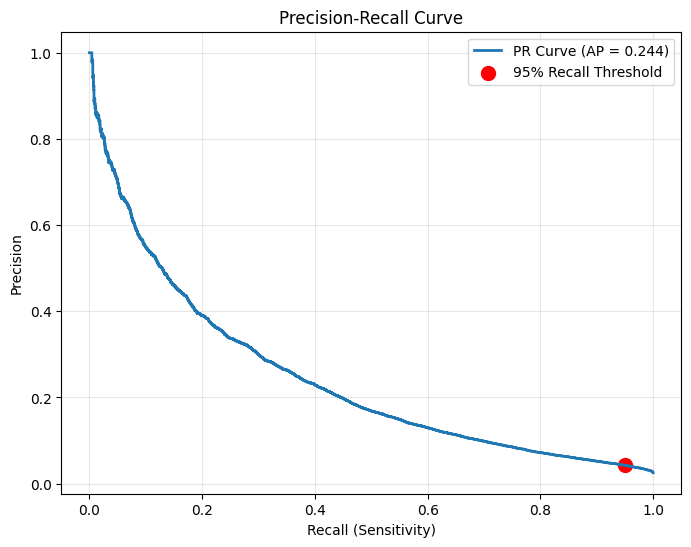

In [39]:
#Recall Curve

# Probabilities
y_prob = best_model.predict_proba(X_test_enc)[:, 1]

# PR curve
precisions, recalls, thresholds = precision_recall_curve(
    y_test_enc,
    y_prob
)

ap = average_precision_score(y_test_enc, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, linewidth=2,
         label=f'PR Curve (AP = {ap:.3f})')

# Mark the 95% recall operating point
plt.scatter(
    0.95,
    0.0426,
    color='red',
    s=100,
    label='95% Recall Threshold'
)

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

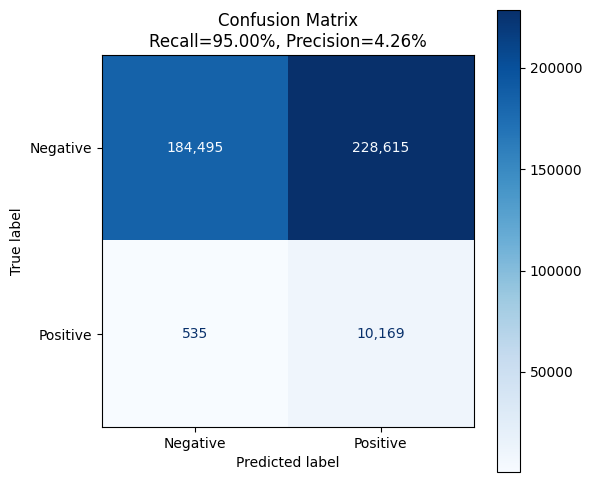

In [40]:
#Confusion Matrix

cm = confusion_matrix(y_test_enc, y_pred_95)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax,values_format=',d')

plt.title(
    f"Confusion Matrix\nRecall={0.95:.2%}, Precision={0.0426:.2%}"
)
plt.show()

In [41]:
for target in [0.90, 0.95]:
    print(f"\nTarget Recall: {target:.0%}")
    print(f"Actual Recall: {operating_points[target]['recall']:.4f}")
    print(f"Precision: {operating_points[target]['precision']:.4f}")
    print(f"Threshold: {operating_points[target]['threshold']:.6f}")


Target Recall: 90%
Actual Recall: 0.9000
Precision: 0.0520
Threshold: 0.012169

Target Recall: 95%
Actual Recall: 0.9500
Precision: 0.0426
Threshold: 0.007738


In [42]:
#What is the positivity rate in the test set?
positivity_rate = y_test_enc.mean()

print(f"Test positivity rate: {positivity_rate:.4%}")

Test positivity rate: 2.5256%


In [43]:
#what share of all tests would we have to do in order to capture 90% or 95% of all positives?

for target in [0.90, 0.95]:

    valid_idx = np.where(recalls >= target)[0]
    best_idx = valid_idx[np.argmax(precisions[valid_idx])]

    threshold = thresholds[min(best_idx, len(thresholds)-1)]

    y_pred = (
        best_model.predict_proba(X_test_enc)[:,1]
        >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_enc,
        y_pred
    ).ravel()

    pct_tested = (tp + fp) / len(y_test_enc)

    print(f"\nTarget Recall: {target:.0%}")
    print(f"Actual Recall: {tp/(tp+fn):.2%}")
    print(f"Precision: {tp/(tp+fp):.2%}")
    print(f"Population Tested: {pct_tested:.2%}")


Target Recall: 90%
Actual Recall: 90.00%
Precision: 5.20%
Population Tested: 43.74%

Target Recall: 95%
Actual Recall: 95.00%
Precision: 4.26%
Population Tested: 56.34%


In [82]:
#Feature importance
feature_names = encoder.get_feature_names_out()

In [83]:
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": best_model.feature_importances_
})

importance_df["importance_pct"] = (
    importance_df["importance"] /
    importance_df["importance"].sum()
) * 100

importance_df["base_feature"] = (
    importance_df["feature"]
    .str.replace(r"^(categorical__|remainder__)", "", regex=True)
    .str.split("_")
    .str[0]
)

In [84]:
#Feature importance
feature_summary = (
    importance_df
    .groupby("base_feature")["importance_pct"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

feature_summary = feature_summary[
    feature_summary["base_feature"] != "County"
]

feature_summary.head(20)

,base_feature,importance_pct
1,PartnerHIVStatus,9.688415
2,MaritalStatus,7.833863
3,TestedHIVBefore,7.002856
4,TBStatus,6.976705
5,ReceivedServices,4.626419
6,CurrentlyOnPrep,4.549292
7,BreastfeedingMother,4.394511
8,PatientDisabled,3.995717
9,ScreenedTB,3.597278
10,dayofweek,2.937161


The model appears to rely heavily on:

- Known HIV risk factors: PartnerHIVStatus, MultiplePartners, UnknownStatusPartner, SexuallyActive.
- Previous HIV testing history: TestedHIVBefore, MonthsSinceLastTest.
- Clinical indicators: TBStatus, ScreenedTB.
- Prevention and service utilization: CurrentlyOnPrep, ReceivedServices.
- Maternal health indicators: Pregnant, BreastfeedingMother, MothersStatus.

In [45]:
#Checking sensitivity for Sex
threshold = threshold_90

y_prob = best_model.predict_proba(X_test_enc)[:,1]
y_pred = (y_prob >= threshold).astype(int)

for sex in X_test["Sex"].unique():

    mask = X_test["Sex"] == sex

    precision = precision_score(
        y_test_enc[mask],
        y_pred[mask],
        zero_division=0
    )

    recall = recall_score(
        y_test_enc[mask],
        y_pred[mask],
        zero_division=0
    )

    prevalence = y_test_enc[mask].mean()

    print(
        f"{sex}: "
        f"Prevalence={prevalence:.2%}, "
        f"Precision={precision:.2%}, "
        f"Recall={recall:.2%}"
    )

F: Prevalence=2.31%, Precision=5.13%, Recall=89.29%
M: Prevalence=3.00%, Precision=5.32%, Recall=91.22%


In [46]:
X_test.columns

Index(['PopulationType', 'KeyPopulation', 'PriorityPopulation',
       'IsHealthWorker', 'TestedHIVBefore', 'ResultOfHIV', 'EverHadSex',
       'SexuallyActive', 'NewPartner', 'PartnerHIVStatus', 'MultiplePartners',
       'AlcoholSex', 'MoneySex', 'CondomBurst', 'UnknownStatusPartner',
       'KnownStatusPartner', 'Pregnant', 'BreastfeedingMother',
       'ExperiencedViolenceScreening', 'CurrentlyOnPrep',
       'TraditionalProcedures', 'MothersStatus', 'ResultOfHIVSelf',
       'ScreenedTB', 'TBStatus', 'ReceivedServices', 'ViolenceScreeningType',
       'Sex', 'MaritalStatus', 'PatientDisabled', 'EverTestedForHiv',
       'MonthsSinceLastTest', 'PriorityPopulationType', 'County', 'Age',
       'GBVSexual', 'GBVPhysical', 'GBVEmotional', 'ReceivedPREP',
       'ReceivedTB', 'ReceivedSTI', 'dayofweek'],
      dtype='str')

In [47]:

#Checking sensitivity for population types

test_df = sparse["sparse_test"].copy()


test_df["actual"] = y_test_enc.values if hasattr(y_test_enc, "values") else y_test_enc
test_df["predicted"] = y_pred_90

results = []

for pop in test_df["PopulationType"].dropna().unique():

    mask = test_df["PopulationType"] == pop

    prevalence = test_df.loc[mask, "actual"].mean()

    precision = precision_score(
        test_df.loc[mask, "actual"],
        test_df.loc[mask, "predicted"],
        zero_division=0
    )

    recall = recall_score(
        test_df.loc[mask, "actual"],
        test_df.loc[mask, "predicted"],
        zero_division=0
    )

    results.append({
        "PopulationType": pop,
        "N": mask.sum(),
        "Prevalence (%)": prevalence * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "Lift": precision / prevalence if prevalence > 0 else None
    })

population_results = (
    pd.DataFrame(results)
    .sort_values("Lift", ascending=False)
)

population_results.round(2)

,PopulationType,N,Prevalence (%),Precision (%),Recall (%),Lift
1,KP,30781,1.25,4.34,77.66,3.47
2,PRIORITY,14174,1.38,4.53,86.22,3.27
0,GP,378859,2.67,5.24,90.55,1.96


In [48]:
#Checking sensitivity for population types

test_df = sparse["sparse_test"].copy()

test_df["actual"] = y_test_enc.values if hasattr(y_test_enc, "values") else y_test_enc
test_df["predicted"] = y_pred_90

results = []

for county in test_df["County"].dropna().unique():

    mask = test_df["County"] == county

    recall = recall_score(
        test_df.loc[mask, "actual"],
        test_df.loc[mask, "predicted"],
        zero_division=0
    )

    positives = test_df.loc[mask, "actual"].sum()

    results.append({
        "County": county,
        "N": mask.sum(),
        "Positive Cases": positives,
        "Sensitivity (%)": recall * 100
    })

county_results_90 = (
    pd.DataFrame(results)
    .sort_values("Sensitivity (%)", ascending=False)
)

county_results_90.round(2)

,County,N,Positive Cases,Sensitivity (%)
36,Samburu,141,16,100.00
38,Turkana,19,5,100.00
39,Baringo,396,64,100.00
35,West Pokot,37,31,100.00
30,Kajiado,2657,204,98.53
26,Bomet,2989,214,97.66
15,Laikipia,1475,66,96.97
31,Busia,3516,134,96.27
20,Nyamira,1412,65,95.38
32,Nandi,1855,129,95.35


County Specific Threshholds

In [58]:
test_df = sparse["sparse_test"].copy()

test_df["actual"] = y_test_enc.values if hasattr(y_test_enc, "values") else y_test_enc
test_df["score"] = y_prob   # predicted probabilities

In [59]:
from sklearn.metrics import roc_curve

county_thresholds = []

for county in sorted(test_df["County"].dropna().unique()):

    county_df = test_df[test_df["County"] == county]

    positives = county_df["actual"].sum()

    # Need at least 1 positive and 1 negative case
    if county_df["actual"].nunique() < 2:
        continue

    fpr, tpr, thresholds = roc_curve(
        county_df["actual"],
        county_df["score"]
    )

    idx90 = np.abs(tpr - 0.90).argmin()
    idx95 = np.abs(tpr - 0.95).argmin()

    county_thresholds.append({
        "County": county,
        "N": len(county_df),
        "Positive Cases": int(positives),
        "Threshold_90": thresholds[idx90],
        "Sensitivity_90": tpr[idx90] * 100,
        "Threshold_95": thresholds[idx95],
        "Sensitivity_95": tpr[idx95] * 100
    })

county_thresholds_df = (
    pd.DataFrame(county_thresholds)
    .sort_values("County")
    .reset_index(drop=True)
)

county_thresholds_df.round(4)

,County,N,Positive Cases,Threshold_90,Sensitivity_90,Threshold_95,Sensitivity_95
0,Baringo,396,64,0.0758,90.6250,0.0578,95.3125
1,Bomet,2989,214,0.0275,90.1869,0.0210,94.8598
2,Bungoma,5585,203,0.0146,90.1478,0.0117,95.0739
3,Busia,3516,134,0.0173,90.2985,0.0146,94.7761
4,Elgeyo Marakwet,74,2,0.0086,100.0000,0.0086,100.0000
5,Embu,3381,92,0.0152,90.2174,0.0102,94.5652
6,Homa Bay,25208,993,0.0161,90.0302,0.0110,94.9648
7,Kajiado,2657,204,0.0429,90.1961,0.0333,95.0980
8,Kakamega,8065,301,0.0153,90.0332,0.0094,95.0166
9,Kericho,2725,117,0.0254,89.7436,0.0133,94.8718


In [60]:
#Save the County specific threshholds
county_thresholds_df.to_excel(
    "County_Specific_Thresholds.xlsx",
    index=False
)

In [ ]:
from google.colab import files
files.download("County_Specific_Thresholds.xlsx")

In [66]:
#Save overall threshholds


overall_thresholds = pd.DataFrame({
    "Target_Sensitivity": ["90%", "95%"],
    "Threshold": [threshold_90, threshold_95]
})

overall_thresholds

overall_thresholds.to_excel(
    "overall_thresholds.xlsx",
    index=False
)


In [67]:
#Download
files.download("overall_thresholds.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>